--- آمار توصیفی سن ---
تعداد             6064.000000
میانگین             53.850099
میانه               57.000000
انحراف معیار        17.183330
حداقل               20.000000
چارک اول (25%)      39.000000
چارک سوم (75%)      68.000000
حداکثر              80.000000
dtype: float64


C:\Users\reg\AppData\Local\Temp\ipykernel_18484\125202018.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['RIAGENDR'], palette='pastel')


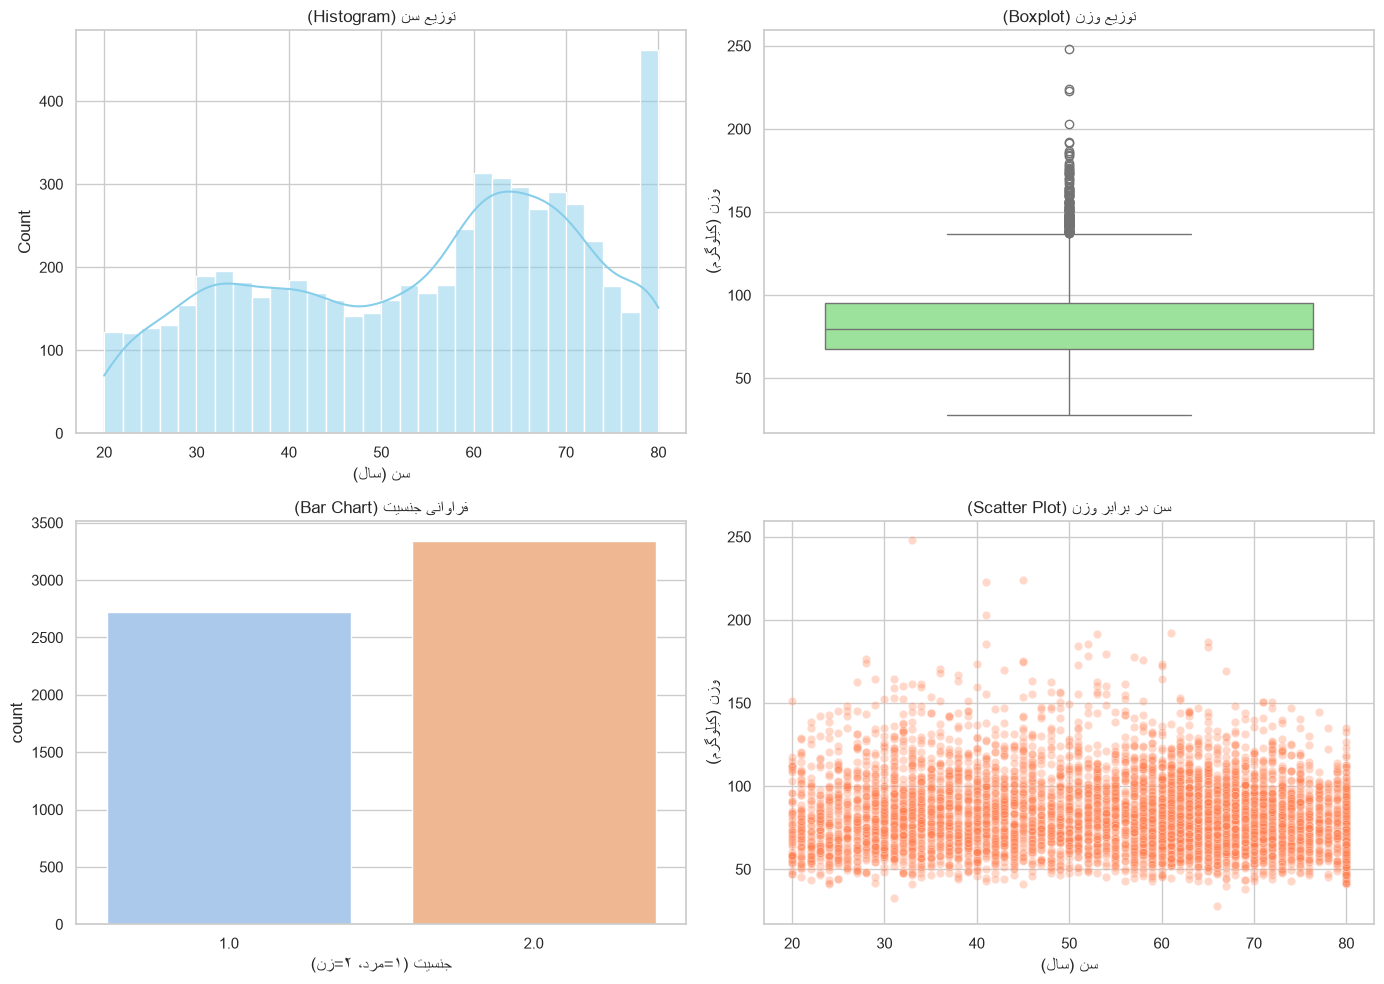

In [1]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# اتصال به پوشه src و فراخوانی کلاس
sys.path.append(os.path.abspath('../src'))
from nhanes_analyzer import NhanesAnalyzer

# نمونه‌سازی و آماده‌سازی داده‌ها (مسیر فایل‌های داده را بررسی کنید)
analyzer = NhanesAnalyzer('../data/DEMO_L.XPT', '../data/BMX_L.XPT')
analyzer.merge_files()
analyzer.define_population(min_age=20)
df = analyzer.analytical_population

# چاپ آمار توصیفی برای سن[cite: 6]
print("--- آمار توصیفی سن ---")
print(analyzer.get_descriptive_stats('RIDAGEYR'))

# رسم ۴ نمودار معنادار در یک قاب[cite: 6]
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 10))

# ۱. نمودار هیستوگرام (توزیع سن)
plt.subplot(2, 2, 1)
sns.histplot(df['RIDAGEYR'], bins=30, kde=True, color='skyblue')
plt.title('توزیع سن (Histogram)')
plt.xlabel('سن (سال)')

# ۲. نمودار باکس‌پلات (پراکندگی و نقاط دورافتاده وزن)
plt.subplot(2, 2, 2)
sns.boxplot(y=df['BMXWT'], color='lightgreen')
plt.title('توزیع وزن (Boxplot)')
plt.ylabel('وزن (کیلوگرم)')

# ۳. نمودار میله‌ای (فراوانی متغیر طبقه‌ای مثل جنسیت)
plt.subplot(2, 2, 3)
sns.countplot(x=df['RIAGENDR'], palette='pastel')
plt.title('فراوانی جنسیت (Bar Chart)')
plt.xlabel('جنسیت (۱=مرد، ۲=زن)')

# ۴. نمودار پراکندگی (ارتباط اولیه دو متغیر کمی)
plt.subplot(2, 2, 4)
sns.scatterplot(x=df['RIDAGEYR'], y=df['BMXWT'], alpha=0.3, color='coral')
plt.title('سن در برابر وزن (Scatter Plot)')
plt.xlabel('سن (سال)')
plt.ylabel('وزن (کیلوگرم)')

plt.tight_layout()
plt.show()

In [2]:
import numpy as np

# ۱. مقایسه توصیفی (تسک ۹)
print("--- مقایسه میانگین وزن بر اساس جنسیت (۱=مرد، ۲=زن) ---")
group_stats = df.groupby('RIAGENDR')['BMXWT'].mean()
print(group_stats)
print("\n")

# ۲. محاسبه میانگین خام در برابر میانگین وزن‌دار (الزام الف.۳)[cite: 7]
# فیلتر کردن رکوردهایی که مقادیر وزن نمونه‌گیری یا متغیر هدف در آن‌ها خالی نیست
valid_data = df.dropna(subset=['BMXWT', 'WTINT2YR'])

raw_mean = valid_data['BMXWT'].mean()
weighted_mean = np.average(valid_data['BMXWT'], weights=valid_data['WTINT2YR'])

print("--- اثر طراحی پیمایش بر برآوردها ---")
print(f"میانگین خام (ساده): {raw_mean:.2f}")
print(f"میانگین وزن‌دار (جمعیتی): {weighted_mean:.2f}")

--- مقایسه میانگین وزن بر اساس جنسیت (۱=مرد، ۲=زن) ---
RIAGENDR
1.0    89.376897
2.0    78.328064
Name: BMXWT, dtype: float64


--- اثر طراحی پیمایش بر برآوردها ---
میانگین خام (ساده): 83.29
میانگین وزن‌دار (جمعیتی): 84.16
